## TASK 2: 

The goal of this other task is to also train and tune classic machine learning algorithms but this time with two different datasets. We will do classification for both the whole song and then for segments of these songs. This will allow us to compare their performance and answer some questions: 

- Q5 (mandatory): Is the 3 s accuracy real or inflated? 

- Q1: s 3 seconds enough to identify a genre? 

- Q2: Combining the short windows improves the whole window results? 

- Q4: Does position within the clip matter?

In [ ]:
!git clone https://github.com/annacp04/music-genre-classification.git
%cd music-genre-classification

In [1]:
from Preprocessing import * 

In [2]:
feat_30_df = pd.read_csv('features_30_sec.csv', sep=',')
feat_3_df = pd.read_csv('features_3_sec.csv', sep=',')
target_column = "label"

In [3]:
feat_3_df.head()

,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.0.wav,66149,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,...,39.687145,-3.241280,36.488243,0.722209,38.099152,-5.050335,33.618073,-0.243027,43.771767,blues
1,blues.00000.1.wav,66149,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,...,64.748276,-6.055294,40.677654,0.159015,51.264091,-2.837699,97.030830,5.784063,59.943081,blues
2,blues.00000.2.wav,66149,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,...,67.336563,-1.768610,28.348579,2.378768,45.717648,-1.938424,53.050835,2.517375,33.105122,blues
3,blues.00000.3.wav,66149,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,...,47.739452,-3.841155,28.337118,1.218588,34.770935,-3.580352,50.836224,3.630866,32.023678,blues
4,blues.00000.4.wav,66149,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,...,30.336359,0.664582,45.880913,1.689446,51.363583,-3.392489,26.738789,0.536961,29.146694,blues


To compare the results between both datasets, it's important to have the same songs in the partitions for both datasets and to make sure that all the segments of the same song are in the same partition (later in the questions we will elaborate more on this). 

In [4]:
# DATASET 30 SEC
prep_30s = Preprocessing(
    feat_30_df,
    y_name="label",
    group_col="filename",
    test_size=0.20,
    random_state=42,
    drop_duplicates=False,
)

prep_30s.run()

test_songs_30s = set(prep_30s.groups_test.unique())


# DATASET 3 SEC
prep_3s = Preprocessing(
    feat_3_df,
    y_name="label",
    group_col="filename",
    test_size=0.20,
    random_state=42,
    test_groups=test_songs_30s, # Use same partition
    drop_duplicates=False,
)

prep_3s.run()

=== Cleaning ===
Songs found: 1000
Dropped columns: ['filename']
Rows without target removed: 0
Final shape: (1000, 61)

X: (1000, 58) | y: (1000,)

=== Train / test split (80% / 20%) ===
Split by song -> train: 800 songs | test: 200 songs
Train: (800, 58) | Test: (200, 58)

Class proportions (train vs test):
           train  test
label                 
blues        0.1   0.1
classical    0.1   0.1
country      0.1   0.1
disco        0.1   0.1
hiphop       0.1   0.1
jazz         0.1   0.1
metal        0.1   0.1
pop          0.1   0.1
reggae       0.1   0.1
rock         0.1   0.1

=== Categorical encoding ===
No categorical features to encode.

=== Constant columns removed (0) ===

=== Target encoding ===
0 -> blues
1 -> classical
2 -> country
3 -> disco
4 -> hiphop
5 -> jazz
6 -> metal
7 -> pop
8 -> reggae
9 -> rock
=== Cleaning ===
Songs found: 1000
Dropped columns: ['filename']
Rows without target removed: 0
Final shape: (9990, 61)

X: (9990, 58) | y: (9990,)

=== Train / test split

In [5]:
def audit_partitions(prep_30s, prep_3s):
    # Checks for leakage between the two datasets and ensures that shared songs are assigned to the same partition.

    train_30 = set(prep_30s.groups_train.unique())
    test_30 = set(prep_30s.groups_test.unique())

    train_3 = set(prep_3s.groups_train.unique())
    test_3 = set(prep_3s.groups_test.unique())

    assert train_30.isdisjoint(test_30), (
        "Leakage in the full-length song dataset"
    )
    assert train_3.isdisjoint(test_3), (
        "Leakage in the song segment dataset"
    )

    shared = (
        (train_30 | test_30)
        & (train_3 | test_3)
    )

    mismatches = {
        song for song in shared
        if ((song in test_30) != (song in test_3))
    }

    assert not mismatches, (
        f"Inconsistent partitions: {len(mismatches)} songs. "
        f"Examples: {list(mismatches)[:10]}"
    )

    print("Audit passed.")
    print(f"Shared songs: {len(shared)}")
    print(f"Train 30 s: {len(train_30)} songs")
    print(f"Test 30 s:  {len(test_30)} songs")
    print(f"Train 3 s:  {len(train_3)} songs")
    print(f"Test 3 s:   {len(test_3)} songs")
    print("There is no train/test overlap.")
    print("Shared songs are assigned to the same partition.")

    return True


In [6]:
audit_partitions(prep_30s, prep_3s)


X_train_30s, X_test_30s, y_train_30s, y_test_30s = (
    prep_30s.get_data()
)

X_train_3s, X_test_3s, y_train_3s, y_test_3s = (
    prep_3s.get_data()
)

meta_train_30s, meta_test_30s = prep_30s.get_meta()
meta_train_3s, meta_test_3s = prep_3s.get_meta()

Audit passed.
Shared songs: 1000
Train 30 s: 800 songs
Test 30 s:  200 songs
Train 3 s:  800 songs
Test 3 s:   200 songs
There is no train/test overlap.
Shared songs are assigned to the same partition.


### Training models for the 30 second dataset:


===== Logistic Regression =====
Best parameters (full train): {'model__C': 1, 'selector': 'passthrough'}

===== KNN =====
Best parameters (full train): {'model__n_neighbors': 13, 'model__weights': 'uniform', 'selector': LinearDiscriminantAnalysis()}

===== Decision Tree =====
Best parameters (full train): {'model__criterion': 'entropy', 'model__max_depth': None, 'model__min_samples_leaf': 1, 'selector': SelectFromModel(estimator=RandomForestClassifier(n_estimators=200, n_jobs=1,
                                                 random_state=42),
                max_features=50, threshold=-inf), 'selector__max_features': 50}

===== ANN (MLP) =====
Best parameters (full train): {'model__alpha': 0.01, 'model__hidden_layer_sizes': (128, 64), 'selector': PCA(n_components=0.95, random_state=42, svd_solver='full'), 'selector__n_components': 0.95}

===== Random Forest =====
Best parameters (full train): {'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'selector': CorrelationFilter

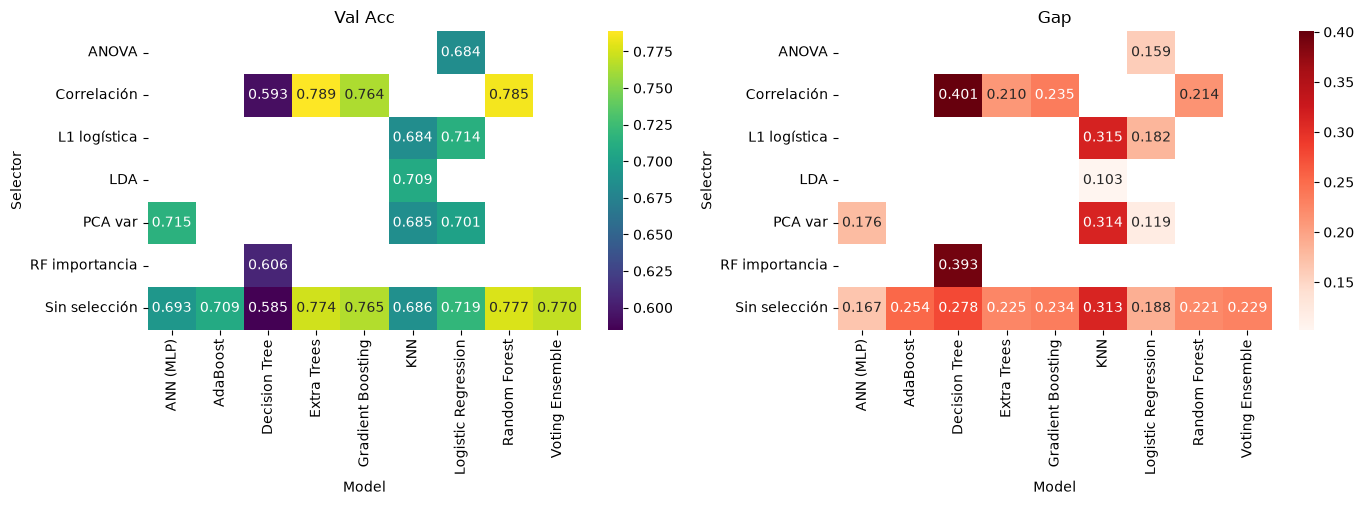

In [7]:
from sklearn.base import clone
from Models import *
from grid_config import *

models_30 = Models(X_train_30s, y_train_30s, label_encoder=prep_30s.encoder, n_splits=10)
models_30.build_models()
grids_30 = build_param_grids(models_30.fs, k_values=(20, 30, 40))

# 1. Grid search (now printing which model each result belongs to)
results_30 = {}
for name, grid in grids_30.items():
    print(f"\n===== {name} =====")
    _, results_30[name] = models_30.grid_search(
        name, grid, nested=False, set_best=False, inner_splits=10
    )

# 2. For each model x selector, keep its best hyperparameters as a pipeline
names_30 = []
for name, summary in results_30.items():
    cv = summary["cv_results"]                          # already sorted by score
    cv = cv.assign(Selector=cv["params"].map(lambda p: selector_label(p["selector"])))
    for _, row in cv.groupby("Selector", sort=False).head(1).iterrows():
        tuned_name = f"{name} | {row['Selector']}"
        pipe = clone(clone(models_30.models[name]).set_params(**row["params"]))
        if tuned_name in models_30.models:              # so the cell can be re-run
            models_30.remove_model(tuned_name)
        models_30.add_model(tuned_name, pipe, model=name, selector=row["Selector"])
        names_30.append(tuned_name)

# 3. Same table as before: train vs validation, gap, F1, number of features
results = models_30.evaluate_all(names=names_30)
best_30 = models_30.best_per_model()
models_30.plot_grid()

Model trained on the full training set: Extra Trees | Correlación
Model: Extra Trees | Correlación
Test accuracy: 0.8000
Test macro F1: 0.7972

Classification report:
              precision    recall  f1-score   support

       blues       0.89      0.85      0.87        20
   classical       0.90      0.90      0.90        20
     country       0.89      0.85      0.87        20
       disco       0.73      0.55      0.63        20
      hiphop       0.74      0.70      0.72        20
        jazz       0.78      0.90      0.84        20
       metal       0.79      0.95      0.86        20
         pop       0.81      0.85      0.83        20
      reggae       0.67      0.70      0.68        20
        rock       0.79      0.75      0.77        20

    accuracy                           0.80       200
   macro avg       0.80      0.80      0.80       200
weighted avg       0.80      0.80      0.80       200



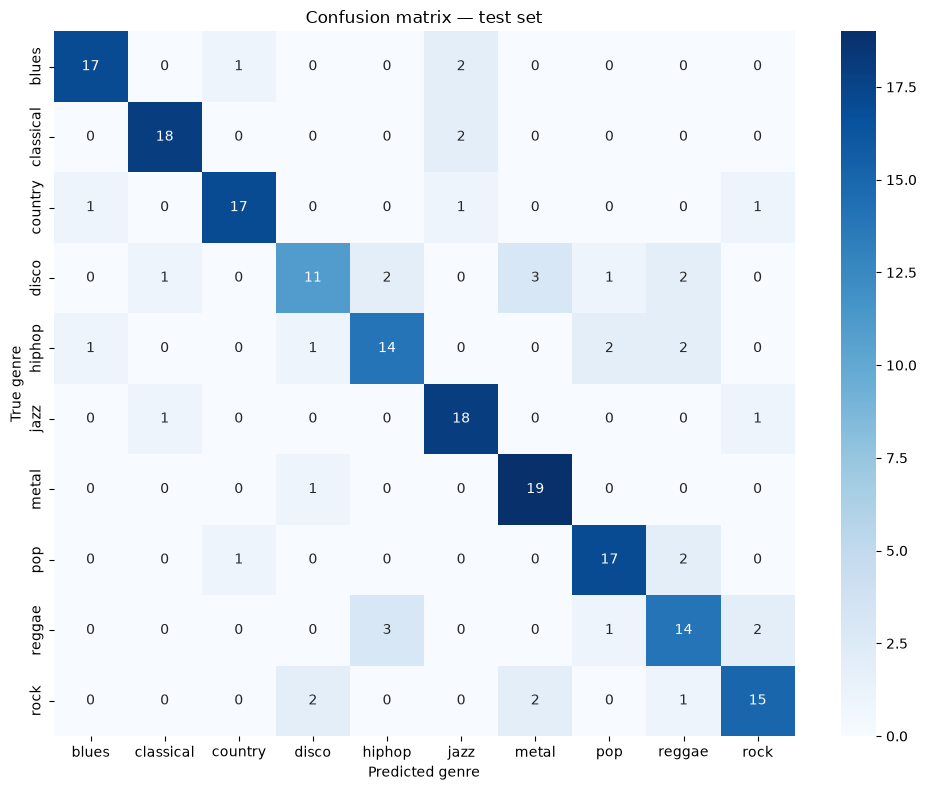

array([0, 2, 0, 5, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 5, 5, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2,
       2, 5, 2, 2, 2, 2, 2, 2, 2, 9, 0, 2, 2, 2, 2, 2, 3, 8, 3, 3, 3, 3,
       7, 1, 3, 4, 4, 8, 3, 6, 3, 6, 3, 6, 3, 3, 8, 4, 4, 4, 0, 3, 8, 4,
       4, 4, 4, 4, 4, 4, 7, 7, 4, 4, 4, 4, 1, 5, 9, 5, 5, 5, 5, 5, 5, 5,
       5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 6, 3, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
       6, 6, 6, 6, 6, 6, 6, 6, 8, 7, 7, 7, 7, 7, 8, 7, 2, 7, 7, 7, 7, 7,
       7, 7, 7, 7, 7, 7, 8, 8, 8, 9, 4, 8, 8, 9, 8, 8, 8, 8, 4, 8, 8, 8,
       4, 8, 7, 8, 9, 9, 6, 8, 9, 9, 9, 3, 9, 3, 9, 9, 9, 9, 9, 9, 9, 9,
       9, 6])

In [8]:
# We take the best model and evaluate it on the test set
best_name = results.loc[0, "Name"]
models_30.fit_best(best_name)
models_30.evaluate_on_test(X_test_30s, y_test_30s)

The best model on the 30 second features is Extra Trees with a correlation filter for feature selection, it reaches a 80% accuracy on the test set. Performance is uneven across genres, the genres that are best recognized are metal, classical and jazz, and this makes sense because they have very specific characteristics that other methods don't have. 

The errors happen in the genres that are more related. For example Hip-Hop and Reggae are confused, rock is confused with metal and disco... Overall, the errors are musically plausible rather than random, which suggests that part of them comes from the real overlap between genres and not only from the model.

#### Overfitting and feature selection (30 s)

The tree ensembles fit the training songs almost perfectly (train ≈ 0.999) and reach 0.76–0.79 in validation, a gap of ≈ 0.21–0.25, similar to Task 1. The Decision Tree is again the clearest case of overfitting (gap ≈ 0.39, validation 0.61). Logistic Regression (gap 0.19) and KNN with LDA (gap 0.10) overfit less, but also reach a lower validation accuracy (≈ 0.71–0.72). Feature selection matters much less than in Task 1, because there are only 58 descriptors instead of 240. For Logistic Regression, using all the features is the best option (0.719, vs 0.714 with L1, 0.701 with PCA and 0.684 with ANOVA). The correlation filter only adds about one point to the tree ensembles (Extra Trees 0.789 vs 0.774). Only KNN clearly benefits from reducing the dimensions (LDA 0.709 vs 0.686).

### Training models for the 3 second dataset:

              Model  Combinaciones  Fits (nested=False)  Fits (nested=True)
        Extra Trees              4                   40                 440
      Random Forest              4                   40                 440
    Voting Ensemble              2                   20                 220
Logistic Regression              3                   30                 330
          ANN (MLP)              8                   80                 880
                KNN              4                   40                 440
              TOTAL             25                  250                2750

===== Extra Trees =====
Best parameters (full train): {'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'selector': CorrelationFilter(), 'selector__threshold': 0.9}
(31 s)

===== Random Forest =====
Best parameters (full train): {'model__max_features': 0.2, 'model__min_samples_leaf': 1, 'selector': CorrelationFilter(), 'selector__threshold': 0.9}
(103 s)

===== Voting Ensemble

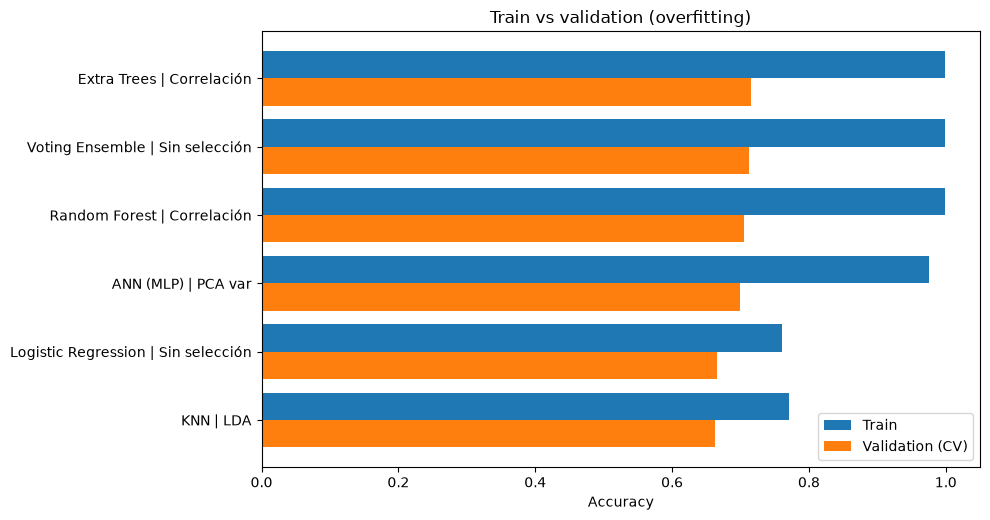

In [9]:
import time
from sklearn.base import clone
from Models import *
from grid_config import *

g_train_3s, g_test_3s = prep_3s.get_groups()

# groups -> song-grouped CV (StratifiedGroupKFold): all the segments of a song
# are always in the same fold, both in the grid search and in evaluate_all
models_3 = Models(
    X_train_3s, y_train_3s, label_encoder=prep_3s.encoder,
    groups=g_train_3s, n_splits=10,
)
models_3.build_models()

# Only the models and selectors that worked best on the 30 s features
SELECTORS_3S = {
    "Extra Trees": ["correlation"],
    "Random Forest": ["correlation"],
    "Voting Ensemble": ["none"],
    "Logistic Regression": ["none"],
    "ANN (MLP)": ["pca_var"],
    "KNN": ["lda"],
}
MODEL_GRIDS_3S = {name: MODEL_GRIDS[name] for name in SELECTORS_3S}
# KNN: k=13 won on 30 s at the edge of the grid -> try larger values; uniform weights only
MODEL_GRIDS_3S["KNN"] = {"model__n_neighbors": [9, 13, 25, 51], "model__weights": ["uniform"]}

grids_3 = build_param_grids(
    models_3.fs, model_grids=MODEL_GRIDS_3S, selectors_per_model=SELECTORS_3S
)
print_grid_sizes(grids_3)

# 1. Grid search
results_3 = {}
for name, grid in grids_3.items():
    print(f"\n===== {name} =====")
    t0 = time.time()
    _, results_3[name] = models_3.grid_search(
        name, grid, nested=False, set_best=False, inner_splits=10
    )
    print(f"({time.time() - t0:.0f} s)")

# 2. Best hyperparameters of each model as a pipeline
names_3 = []
for name, summary in results_3.items():
    cv = summary["cv_results"]
    cv = cv.assign(Selector=cv["params"].map(lambda p: selector_label(p["selector"])))
    for _, row in cv.groupby("Selector", sort=False).head(1).iterrows():
        tuned_name = f"{name} | {row['Selector']}"
        pipe = clone(clone(models_3.models[name]).set_params(**row["params"]))
        if tuned_name in models_3.models:
            models_3.remove_model(tuned_name)
        models_3.add_model(tuned_name, pipe, model=name, selector=row["Selector"])
        names_3.append(tuned_name)

# 3. Train vs validation table (segment-level accuracy, song-grouped CV)
results_3s = models_3.evaluate_all(names=names_3)
best_3 = models_3.best_per_model()
models_3.plot_gap()

Model trained on the full training set: Extra Trees | Correlación
Model: Extra Trees | Correlación
Test accuracy: 0.7282
Test macro F1: 0.7233

Classification report:
              precision    recall  f1-score   support

       blues       0.76      0.74      0.75       200
   classical       0.85      0.94      0.89       198
     country       0.73      0.65      0.69       200
       disco       0.62      0.54      0.58       200
      hiphop       0.70      0.64      0.67       200
        jazz       0.77      0.91      0.83       200
       metal       0.76      0.87      0.81       200
         pop       0.78      0.81      0.80       200
      reggae       0.64      0.67      0.65       200
        rock       0.61      0.53      0.57       200

    accuracy                           0.73      1998
   macro avg       0.72      0.73      0.72      1998
weighted avg       0.72      0.73      0.72      1998



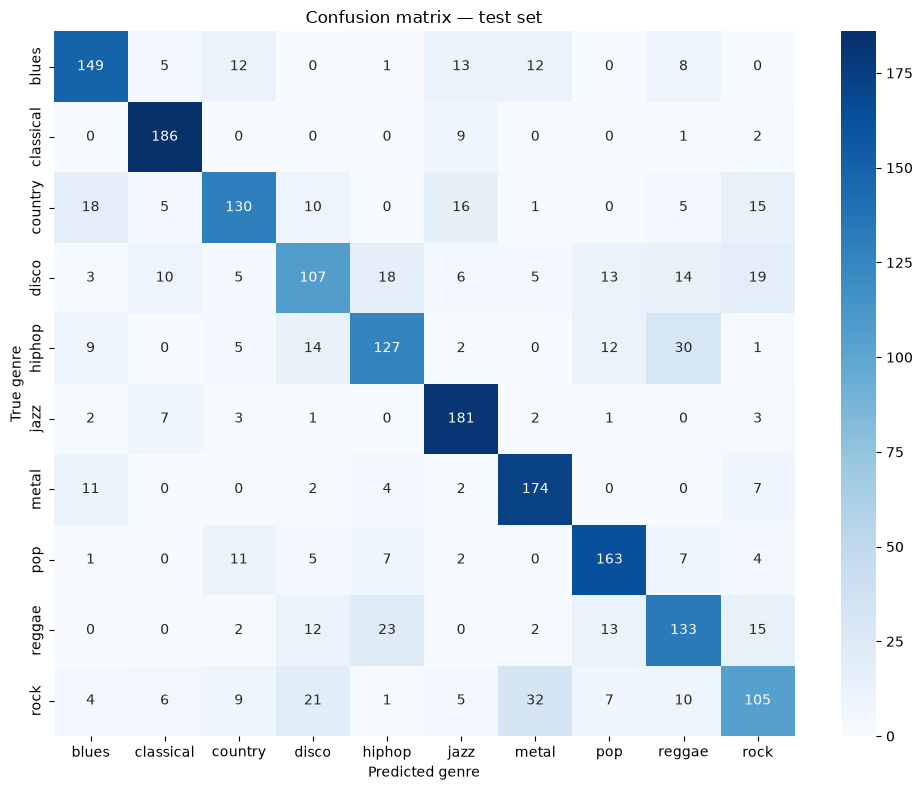

Model: Extra Trees | Correlación
segment    0.7282
mean       0.7800
max        0.7500
vote       0.7800
dtype: float64


{'segment': 0.7282282282282282, 'mean': 0.78, 'max': 0.75, 'vote': 0.78}

In [10]:
best_name_3 = results_3s.loc[0, "Name"]
models_3.fit_best(best_name_3)
models_3.evaluate_on_test(X_test_3s, y_test_3s)
models_3.evaluate_on_test_by_song(X_test_3s, y_test_3s, g_test_3s, hows=("mean", "max", "vote"))

On the 3-second segments the best model is again Extra Trees with the correlation filter (here with max_features="sqrt"), followed closely by the Voting Ensemble and Random Forest. It reaches 0.716 in song-grouped 10-fold CV and 0.728 accuracy / 0.723 macro-F1 on the test set. This is about 7–8 points below the same model on the 30-second features (0.789 CV, 0.800 test), so classifying a single 3-second window is clearly harder than classifying the whole clip. The tree ensembles also show a larger train/validation gap (≈ 0.28–0.29 vs ≈ 0.21 on 30 s): they still fit the training segments almost perfectly (0.999), but each segment is a noisier description of its song, so less of what they learn generalises to new songs. 

The confusion matrix shows the same pattern as with 30 seconds, only amplified. Classical (recall 0.94), jazz (0.91), metal (0.87) and pop (0.81) remain easy to recognise even from 3 seconds, which suggests that their timbre and instrumentation are present in almost every window. The largest drops are for rock (0.75 → 0.53), country (0.85 → 0.65) and blues (0.85 → 0.74), and disco stays the second hardest genre (0.54). The errors again follow musical similarity. Rock is mostly confused with metal (32 segments) and disco (21), and disco with rock (19) and hip-hop (18). Hip-hop and reggae are confused in both directions (30 and 23 segments), and country leaks towards blues (18), jazz (16) and rock (15). A short window often contains only one part of the song (an intro, a guitar riff, a drum pattern), which can sound like a neighbouring genre. The whole clip captures the rhythm and structure over time that separate these genres.

## Experimentation

### 1. Is the 3 s accuracy real or inflated? (QUESTION 5)

In the beginning of the preprocessing, I already had in mind that segments of the same song cannot be in different partitions. In the original preprocessing we divide the 30 second dataset, and use the same indexes of the song to do the same partitions (this way segments of the same song are not in train and test). 

If there where segments of the same song in both partitions, this would boost the accuracy and is called ```DataLeakage```. For the sake of this experiment, I have preprocessed the dataset without the correct separation to evaluate if the accuracy really would inflate if we don't separate the songs well.  

Test songs that also have segments in train: 896 of 896
Evaluating 1 pipelines with 10-fold stratified CV on the training set...
  - Extra Trees | Correlación

CROSS-VALIDATION RESULTS
                     Name  Train Acc  Val Acc  Val Acc Std    Gap  Val F1  N features
Extra Trees | Correlación     0.9992   0.8930       0.0120 0.1062  0.8925     55.0000

Best mean validation accuracy: Extra Trees | Correlación


,Random split (leakage),Split by song,Inflation (points)
Train accuracy,0.999,0.999,0.047
CV accuracy,0.893,0.716,17.741
Test accuracy,0.905,0.728,17.718
Test macro-F1,0.906,0.723,18.226


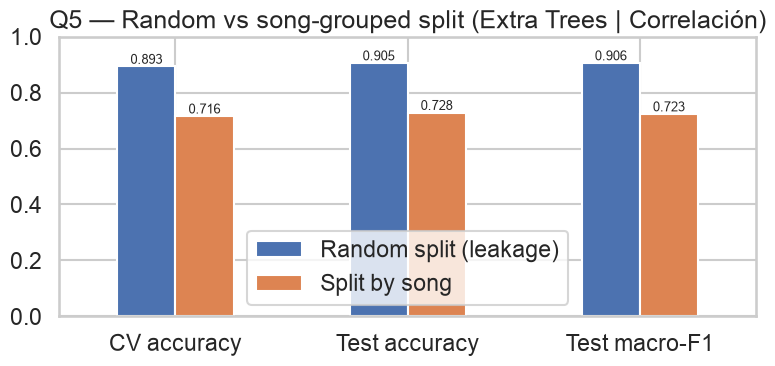

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score

best_pipe = models_3.models[best_name_3]          # best 3 s model: Extra Trees | Correlación

# All 3 s segments, already preprocessed (same features and labels as section 3)
X_all = pd.concat([X_train_3s, X_test_3s], ignore_index=True)
y_all = np.concatenate([np.asarray(y_train_3s), np.asarray(y_test_3s)])
g_all = np.concatenate([g_train_3s, g_test_3s])

# A) Random split by SEGMENT: segments of the same song can be in train and test
tr, te = train_test_split(np.arange(len(y_all)), test_size=0.20, stratify=y_all, random_state=42)
shared = set(g_all[te]) & set(g_all[tr])
print(f"Test songs that also have segments in train: {len(shared)} of {len(set(g_all[te]))}")

# Same model; without groups, Models uses random folds -> leakage inside the CV too
m_leak = Models(X_all.iloc[tr], y_all[tr], n_splits=10)
m_leak.add_model(best_name_3, clone(best_pipe))
leak_cv = m_leak.evaluate_all(names=[best_name_3]).iloc[0]
leak_pred = clone(best_pipe).fit(X_all.iloc[tr], y_all[tr]).predict(X_all.iloc[te])

# B) Split by song: already computed in section 3
group_cv = results_3s.set_index("Name").loc[best_name_3]
group_pred = models_3.best_model.predict(X_test_3s)

q5 = pd.DataFrame(
    {
        "Random split (leakage)": [
            leak_cv["Train Acc"], leak_cv["Val Acc"],
            accuracy_score(y_all[te], leak_pred), f1_score(y_all[te], leak_pred, average="macro"),
        ],
        "Split by song": [
            group_cv["Train Acc"], group_cv["Val Acc"],
            accuracy_score(y_test_3s, group_pred), f1_score(y_test_3s, group_pred, average="macro"),
        ],
    },
    index=["Train accuracy", "CV accuracy", "Test accuracy", "Test macro-F1"],
)
q5["Inflation (points)"] = (q5.iloc[:, 0] - q5.iloc[:, 1]) * 100
display(q5.round(3))

ax = q5.iloc[1:, :2].plot.bar(rot=0, ylim=(0, 1), figsize=(8, 4))
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=9)
ax.set_title(f"Q5 — Random vs song-grouped split ({best_name_3})")
plt.tight_layout()
plt.show()

We can see that the accuracy is clearly inflated when the segments are split randomly. All the segments in the test already had the same song but another part in the training set. The training accuracy is the same in both cases (0.999), so the model learns equally well, and only the evaluation changes. The model can then recognise the song instead of the genre. Leakage also hides overfitting: the train/validation gap looks small (0.11) with the random split but is really 0.28. The leaky result (0.905) would even beat the model trained on the full 30-second clips (0.800), which is not plausible and confirms the leakage. The real 3 s accuracy is therefore about 0.72–0.73.

### 2. Is 3 seconds enough to identify a genre? 

To answer this question we will compare the 30 second dataset performance with the 3 second one. If 3 seconds where enough, we would see a similar performance from both models. 

In the beginning we made sure to have the same partitions so now the comparison is entirely fair. 

,CV 30 s,CV 3 s,Test 30 s,Test 3 s,Δ CV (pts),Δ test (pts)
Model,,,,,,
Extra Trees,0.789,0.716,0.800,0.728,-7.314,-7.177
Random Forest,0.785,0.705,0.805,0.725,-8.040,-8.028
Voting Ensemble,0.770,0.713,0.820,0.729,-5.690,-9.077
Logistic Regression,0.719,0.665,0.755,0.660,-5.358,-9.484
ANN (MLP),0.715,0.699,0.740,0.706,-1.579,-3.379
KNN,0.709,0.662,0.790,0.671,-4.646,-11.883


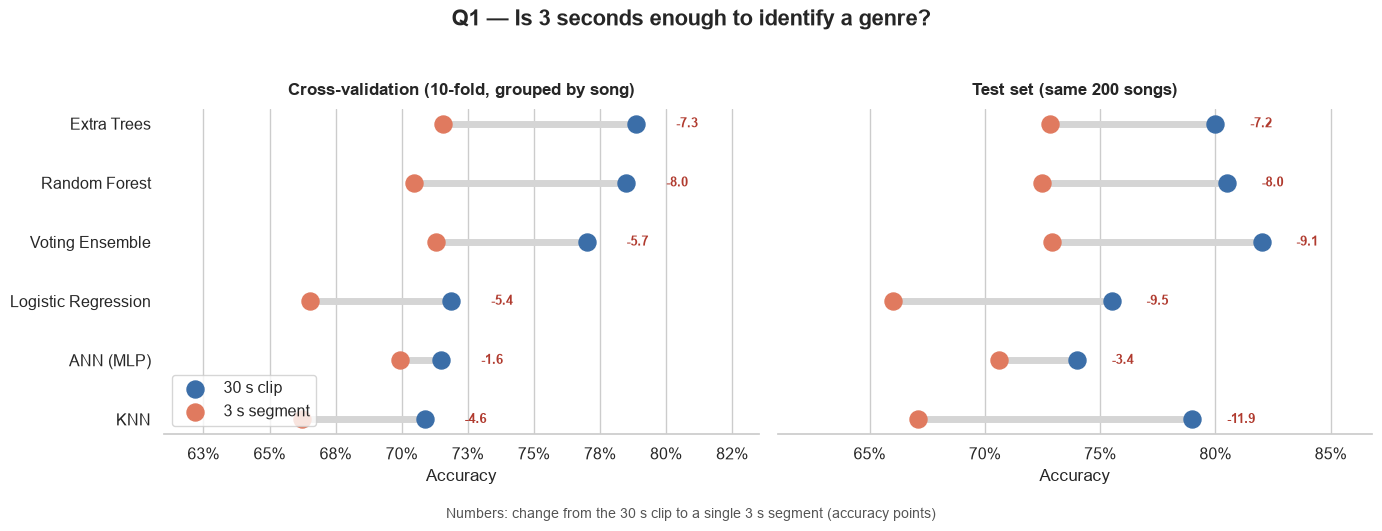

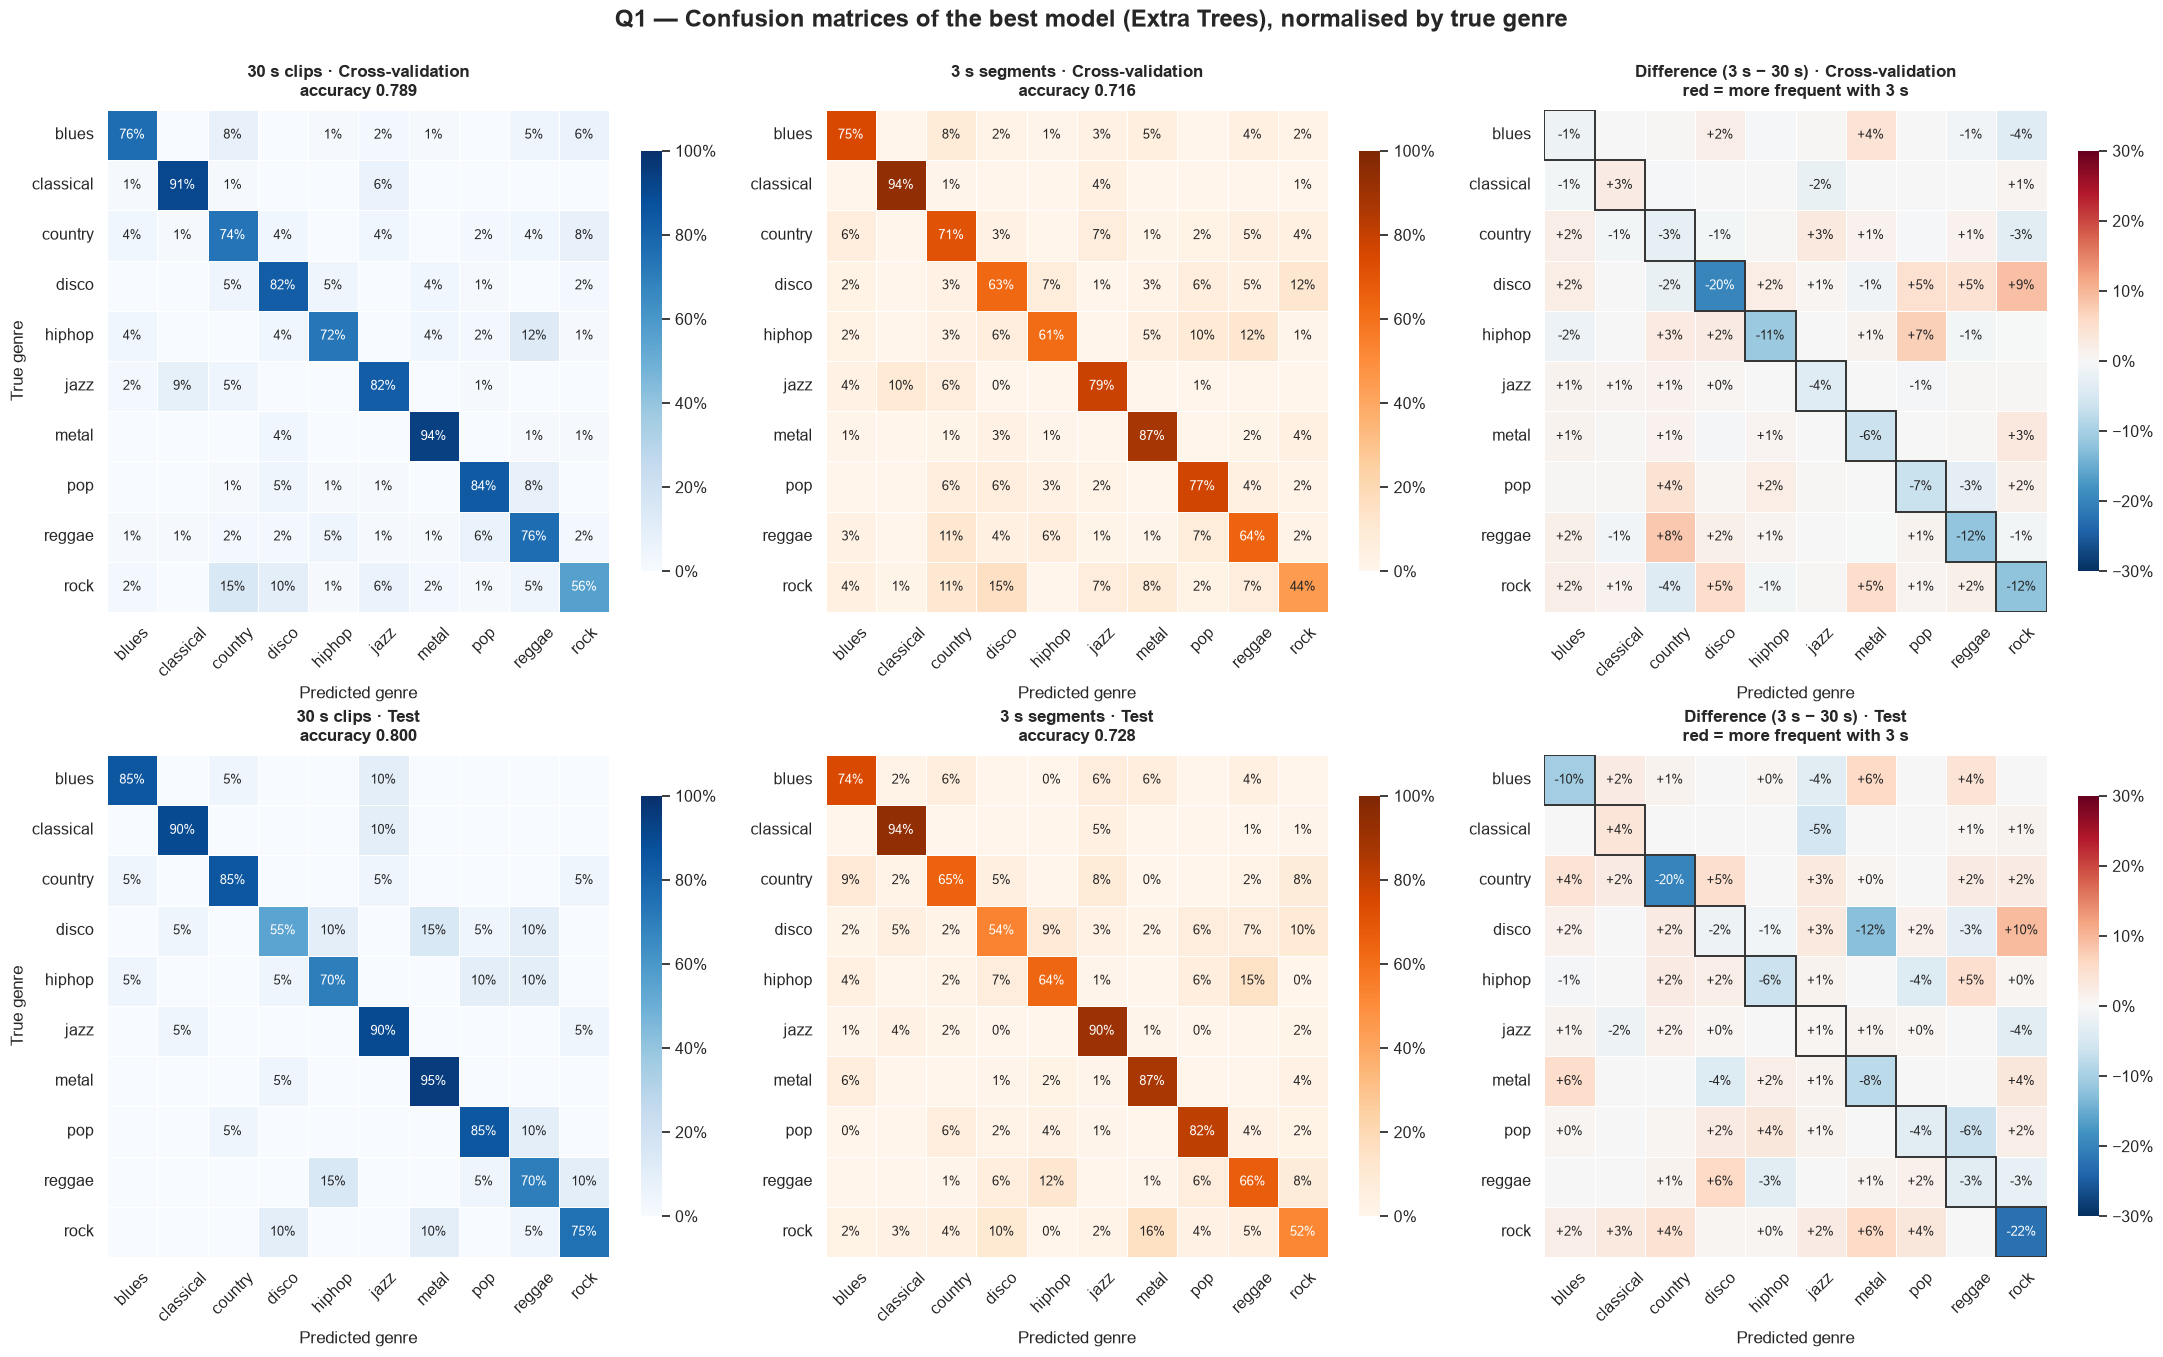

,CV 30 s,CV 3 s,Test 30 s,Test 3 s,Δ CV (pts),Δ test (pts)
disco,0.825,0.626,0.55,0.535,-19.922,-1.500
rock,0.562,0.442,0.75,0.525,-12.014,-22.500
reggae,0.762,0.645,0.70,0.665,-11.750,-3.500
hiphop,0.725,0.614,0.70,0.635,-11.096,-6.500
pop,0.838,0.770,0.85,0.815,-6.750,-3.500
metal,0.938,0.874,0.95,0.870,-6.375,-8.000
jazz,0.825,0.788,0.90,0.905,-3.750,0.500
country,0.738,0.711,0.85,0.650,-2.608,-20.000
blues,0.762,0.748,0.85,0.745,-1.500,-10.500
classical,0.912,0.938,0.90,0.939,2.500,3.939


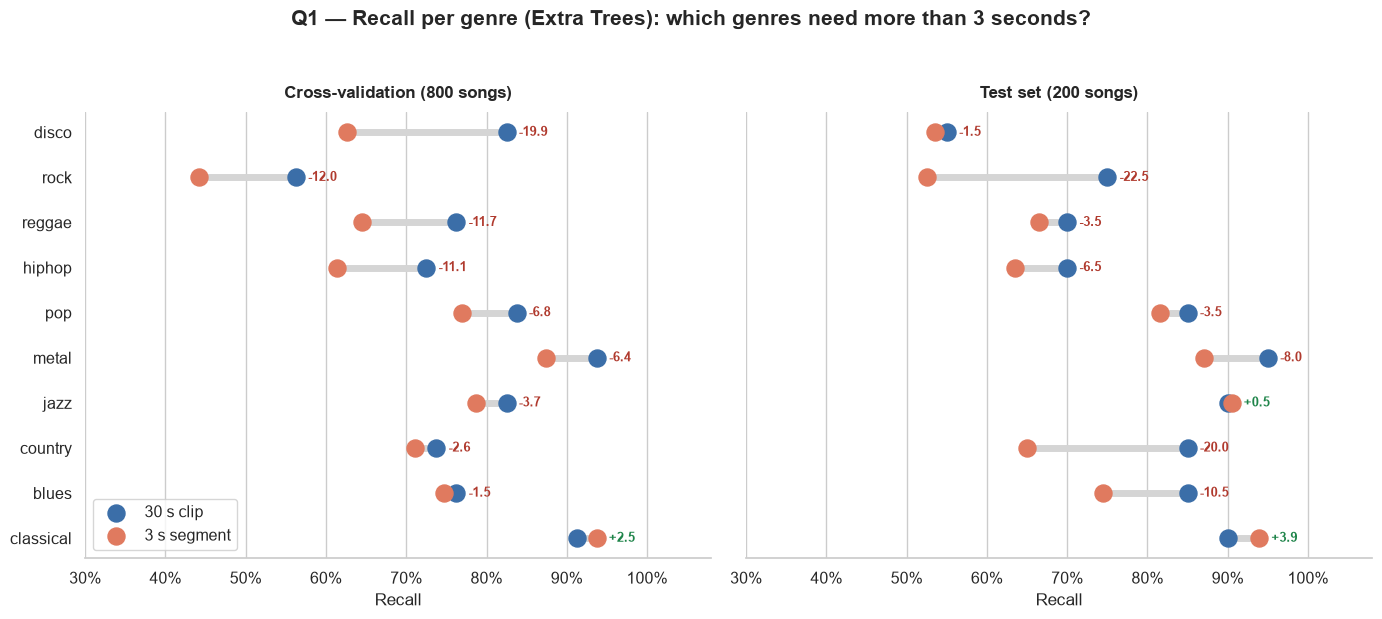

Best model: Extra Trees
Average change across algorithms: CV -5.4 pts, test -8.2 pts


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle
from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
C30, C3 = "#3B6EA8", "#E07A5F"                      # 30 s = blue, 3 s = orange
class_names = np.asarray(prep_30s.encoder.classes_)
labels = np.arange(len(class_names))

# ============================================================
# 1. Same algorithms (tuned on each dataset): CV + test
# ============================================================
rows, fitted = [], {}
for _, r30 in best_30.iterrows():
    r3 = best_3[best_3["Model"] == r30["Model"]]
    if r3.empty:                                    # not run on 3 s (DT, AdaBoost, GB)
        continue
    r3 = r3.iloc[0]
    est30 = clone(models_30.models[r30["Name"]]).fit(models_30.X, models_30.y)
    est3 = clone(models_3.models[r3["Name"]]).fit(models_3.X, models_3.y)
    fitted[r30["Model"]] = {"names": (r30["Name"], r3["Name"]), "est": (est30, est3)}
    rows.append({
        "Model": r30["Model"],
        "CV 30 s": r30["Val Acc"],
        "CV 3 s": r3["Val Acc"],
        "Test 30 s": accuracy_score(y_test_30s, est30.predict(X_test_30s)),
        "Test 3 s": accuracy_score(y_test_3s, est3.predict(X_test_3s)),
    })

q1 = pd.DataFrame(rows).set_index("Model").sort_values("CV 30 s", ascending=False)
q1["Δ CV (pts)"] = (q1["CV 3 s"] - q1["CV 30 s"]) * 100
q1["Δ test (pts)"] = (q1["Test 3 s"] - q1["Test 30 s"]) * 100
display(q1.round(3))


def dumbbell(ax, df, col30, col3, title, xlabel):
    """One row per item: blue dot = 30 s, orange dot = 3 s, label = change in points."""
    d = df.iloc[::-1]                               # first row of df at the top
    y = np.arange(len(d))
    ax.hlines(y, d[col3], d[col30], color="#D5D5D5", lw=5, zorder=1)
    ax.scatter(d[col30], y, s=150, color=C30, zorder=3, label="30 s clip")
    ax.scatter(d[col3], y, s=150, color=C3, zorder=3, label="3 s segment")
    for yi, (a, b) in enumerate(zip(d[col30], d[col3])):
        ax.text(max(a, b) + 0.015, yi, f"{(b - a) * 100:+.1f}", va="center",
                fontsize=9.5, color="#B03A2E" if b < a else "#1E8449", weight="bold")
    ax.set_yticks(y)
    ax.set_yticklabels(d.index)
    ax.set_title(title, weight="bold", pad=10)
    ax.set_xlabel(xlabel)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(axis="y", visible=False)
    sns.despine(ax=ax, left=True)


# ============================================================
# 2. Figure 1 — accuracy per algorithm
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
dumbbell(axes[0], q1, "CV 30 s", "CV 3 s", "Cross-validation (10-fold, grouped by song)", "Accuracy")
dumbbell(axes[1], q1, "Test 30 s", "Test 3 s", "Test set (same 200 songs)", "Accuracy")
lo = q1[["CV 30 s", "CV 3 s", "Test 30 s", "Test 3 s"]].min().min() - 0.05
for ax in axes:
    ax.set_xlim(lo, min(1.0, ax.get_xlim()[1] + 0.04))
axes[0].legend(loc="lower left", frameon=True)
fig.suptitle("Q1 — Is 3 seconds enough to identify a genre?", fontsize=16, weight="bold", y=1.03)
fig.text(0.5, -0.03, "Numbers: change from the 30 s clip to a single 3 s segment (accuracy points)",
         ha="center", fontsize=10, color="#555555")
plt.tight_layout()
plt.show()

# ============================================================
# 3. Figure 2 — confusion matrices of the best model + difference
# ============================================================
best = q1.index[0]
(name30, name3), (est30, est3) = fitted[best]["names"], fitted[best]["est"]

# Out-of-fold CV predictions (each song predicted by a model that never saw it)
proba30, _ = models_30.oof_proba(name30)
proba3, _ = models_3.oof_proba(name3)
preds = {
    ("Cross-validation", "30 s"): (models_30.y, proba30.argmax(1)),
    ("Cross-validation", "3 s"): (models_3.y, proba3.argmax(1)),
    ("Test", "30 s"): (np.asarray(y_test_30s), est30.predict(X_test_30s)),
    ("Test", "3 s"): (np.asarray(y_test_3s), est3.predict(X_test_3s)),
}


def cm_norm(y_true, y_pred):
    return confusion_matrix(y_true, y_pred, labels=labels, normalize="true")


def annotations(cm, signed=False):
    fmt = (lambda v: f"{v:+.0%}") if signed else (lambda v: f"{v:.0%}")
    return np.vectorize(lambda v: "" if abs(v) < 0.005 else fmt(v))(cm)


fig, axes = plt.subplots(2, 3, figsize=(22, 13.5))
for i, split in enumerate(["Cross-validation", "Test"]):
    y30, p30 = preds[(split, "30 s")]
    y3, p3 = preds[(split, "3 s")]
    cm30, cm3 = cm_norm(y30, p30), cm_norm(y3, p3)
    panels = [
        (cm30, f"30 s clips · {split}\naccuracy {accuracy_score(y30, p30):.3f}", "Blues", 0, 1, False),
        (cm3, f"3 s segments · {split}\naccuracy {accuracy_score(y3, p3):.3f}", "Oranges", 0, 1, False),
        (cm3 - cm30, f"Difference (3 s − 30 s) · {split}\nred = more frequent with 3 s", "RdBu_r", -0.3, 0.3, True),
    ]
    for j, (cm, title, cmap, vmin, vmax, signed) in enumerate(panels):
        ax = axes[i, j]
        sns.heatmap(
            cm, annot=annotations(cm, signed), fmt="", cmap=cmap, vmin=vmin, vmax=vmax,
            center=0 if signed else None, square=True, linewidths=0.6, linecolor="white",
            xticklabels=class_names, yticklabels=class_names, annot_kws={"size": 9},
            cbar_kws={"shrink": 0.75, "format": PercentFormatter(1.0, decimals=0)}, ax=ax,
        )
        if signed:                                   # outline the diagonal (recall)
            for k in labels:
                ax.add_patch(Rectangle((k, k), 1, 1, fill=False, edgecolor="#333333", lw=1.4))
        ax.set_title(title, weight="bold", pad=10)
        ax.set_xlabel("Predicted genre")
        ax.set_ylabel("True genre" if j == 0 else "")
        ax.tick_params(axis="x", rotation=45)
        ax.tick_params(axis="y", rotation=0)

fig.suptitle(f"Q1 — Confusion matrices of the best model ({best}), normalised by true genre",
             fontsize=17, weight="bold", y=1.0)
plt.tight_layout()
plt.show()

# ============================================================
# 4. Figure 3 — recall per genre (best model)
# ============================================================
rec = pd.DataFrame(
    {
        "CV 30 s": recall_score(*preds[("Cross-validation", "30 s")], labels=labels, average=None),
        "CV 3 s": recall_score(*preds[("Cross-validation", "3 s")], labels=labels, average=None),
        "Test 30 s": recall_score(*preds[("Test", "30 s")], labels=labels, average=None),
        "Test 3 s": recall_score(*preds[("Test", "3 s")], labels=labels, average=None),
    },
    index=class_names,
)
rec["Δ CV (pts)"] = (rec["CV 3 s"] - rec["CV 30 s"]) * 100
rec["Δ test (pts)"] = (rec["Test 3 s"] - rec["Test 30 s"]) * 100
rec = rec.sort_values("Δ CV (pts)")                 # biggest drop at the top
display(rec.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
dumbbell(axes[0], rec, "CV 30 s", "CV 3 s", "Cross-validation (800 songs)", "Recall")
dumbbell(axes[1], rec, "Test 30 s", "Test 3 s", "Test set (200 songs)", "Recall")
for ax in axes:
    ax.set_xlim(0.3, 1.08)
axes[0].legend(loc="lower left", frameon=True)
fig.suptitle(f"Q1 — Recall per genre ({best}): which genres need more than 3 seconds?",
             fontsize=15, weight="bold", y=1.03)
plt.tight_layout()
plt.show()

print(f"Best model: {best}")
print(f"Average change across algorithms: CV {q1['Δ CV (pts)'].mean():+.1f} pts, "
      f"test {q1['Δ test (pts)'].mean():+.1f} pts")

We can conclude that all the algorithms loose accuracy using the 3 second clips in comparison to the 30 second one. on average 5.4 points in CV and 8.2 points on test (Extra Trees 0.789 → 0.716 in CV and 0.800 → 0.728 on test). 

We can see that the drop is consistent across models, so the problem comes form the representation and not from one algorithm in particular. The MLP loses the least, and it could be because it's the one that benefits the most from having a lot more rows. 

Looking at the confusion matrix, we can see that genres that are defined by timbre and instrumentation are reconized like in the 30 second version (the classical genre even improves a little bit), this could be because almost every window contains their characteristic. The genres that suffer most are disco, rock, reggae and hiphop (that were the ones with more problems even in the beginning). These genres are defined by rhythm, groove and song structure, which a 3-second window cannot capture (descriptors such as tempo are also hard to estimate reliably on such a short window). 

In short, 3 seconds are enough for a reasonable guess and for timbre-defined genres, but not to match the whole clip, especially for genres whose identity unfolds over time.

### 3. Combining the short windows improves the whole window results? 

This question can be interpreted as two different things:
- Combining the predictions of the segments
- Combining the features before training the models

In our case we are going to evaluate the first one. We will see if with different combinations of the predicted probabilities of the segments (via the mean, or a vote...) will improve the results and maybe get better results than the long windows. 

Model: Extra Trees


,CV acc,Test acc,CV macro-F1,Test macro-F1
30 s clip,0.789,0.800,0.787,0.797
3 s segment,0.716,0.728,0.712,0.723
3 s mean,0.765,0.780,0.762,0.775
3 s vote,0.769,0.775,0.766,0.768
3 s max,0.742,0.750,0.736,0.741
3 s log-sum,0.769,0.775,0.766,0.771


,Only 30 s right,Only 3 s right,p-value (McNemar)
Method,,,
3 s mean,60,41,0.0728
3 s vote,60,44,0.1410
3 s max,79,42,0.0010
3 s log-sum,57,41,0.1293


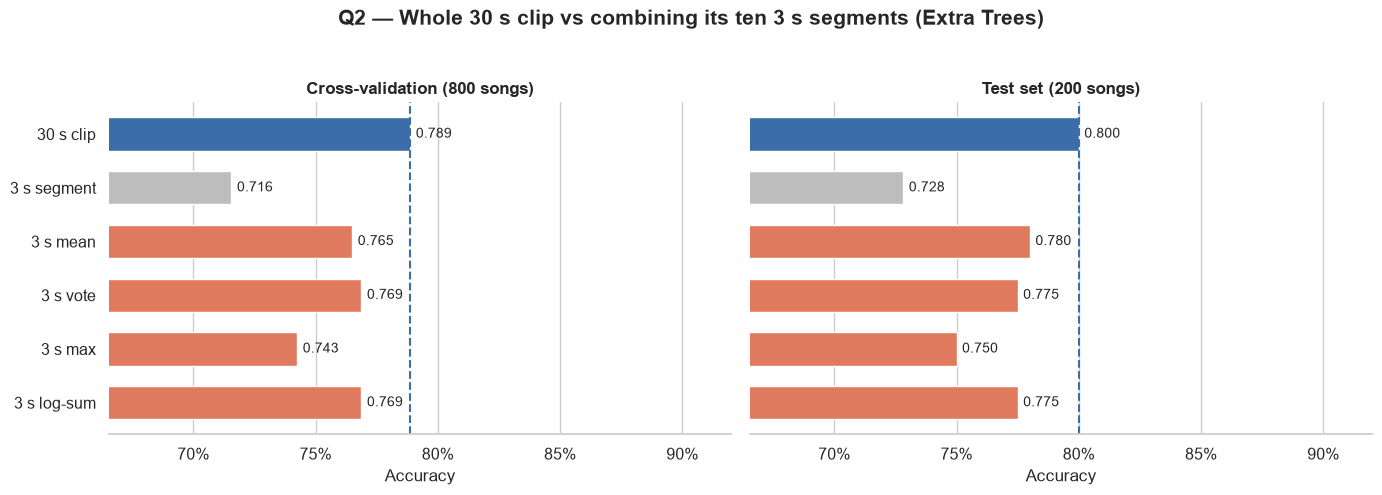

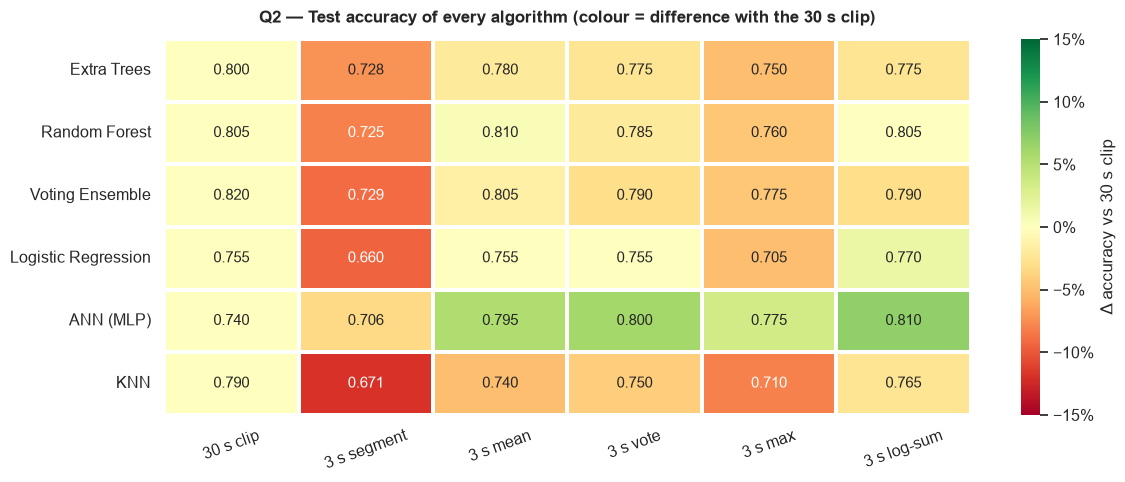

,CV 30 s,CV 3 s mean,Test 30 s,Test 3 s mean,Δ CV (pts)
disco,0.825,0.675,0.55,0.55,-15.00
hiphop,0.725,0.612,0.70,0.55,-11.25
reggae,0.762,0.675,0.70,0.70,-8.75
pop,0.838,0.800,0.85,0.80,-3.75
rock,0.562,0.525,0.75,0.65,-3.75
metal,0.938,0.925,0.95,0.95,-1.25
jazz,0.825,0.825,0.90,0.95,0.00
blues,0.762,0.800,0.85,0.85,3.75
classical,0.912,0.988,0.90,1.00,7.50
country,0.738,0.825,0.85,0.80,8.75


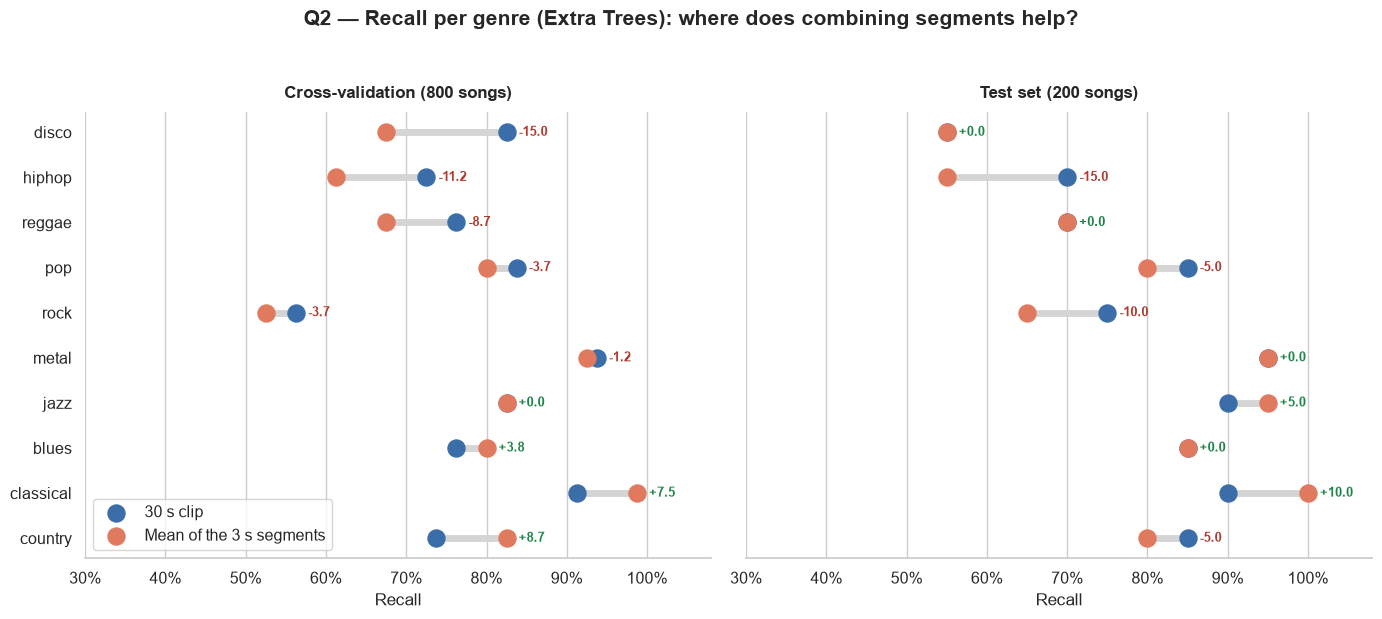

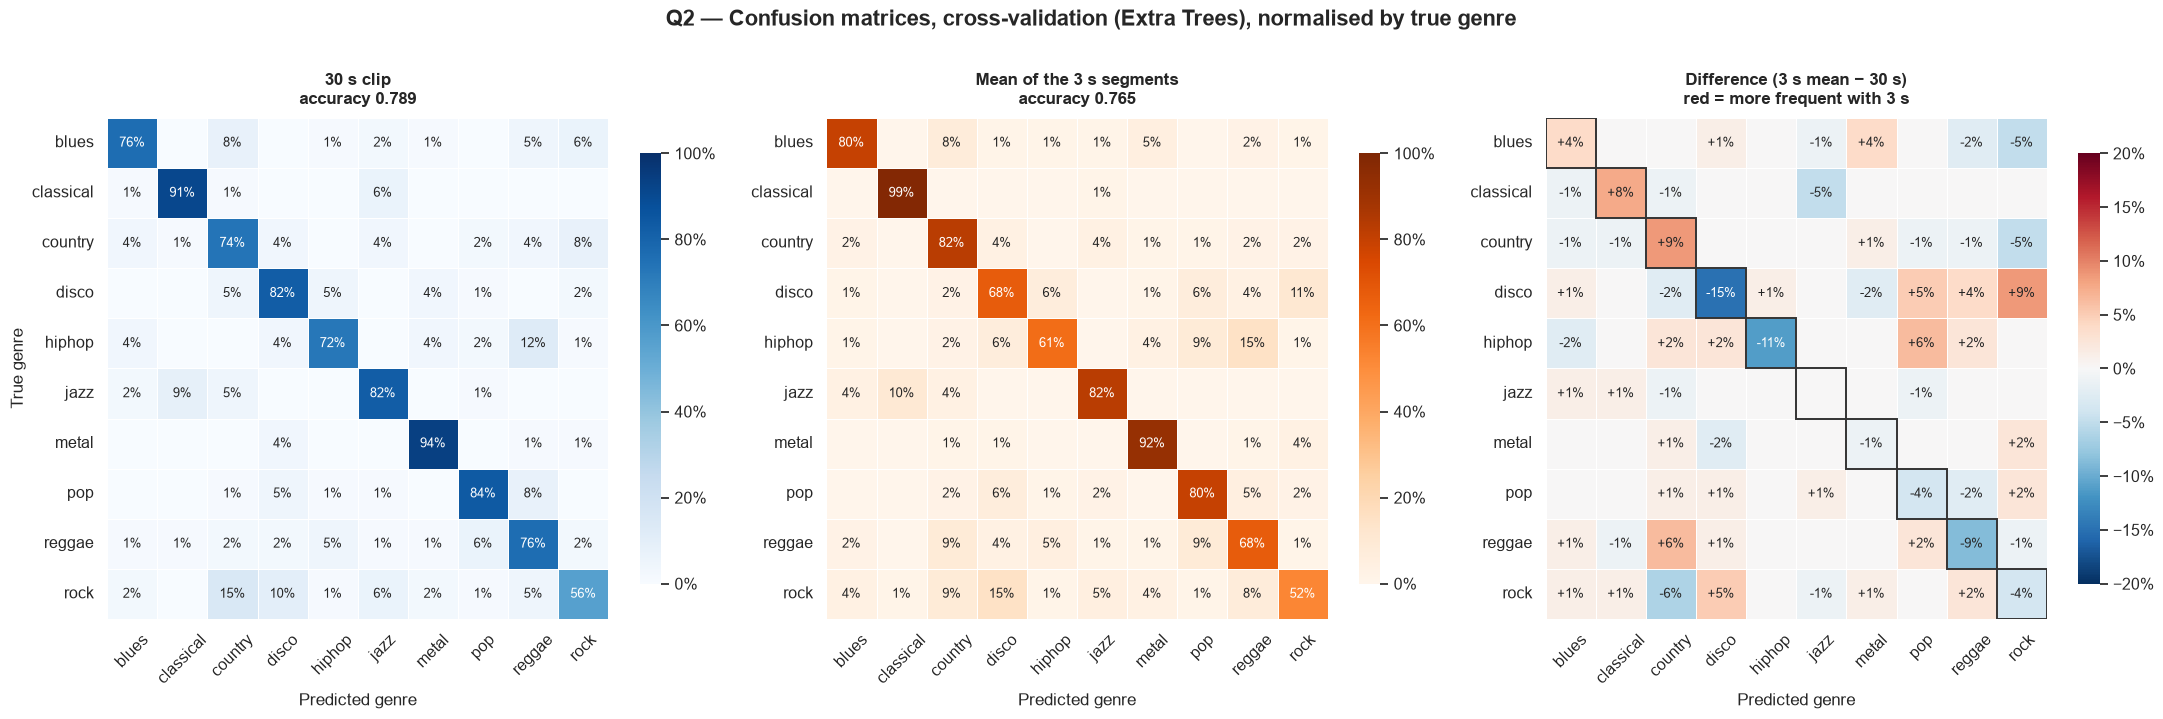

Best combination: 3 s vote | CV 0.769 vs 30 s 0.789 | test 0.775 vs 30 s 0.800


In [17]:
from scipy import stats
from sklearn.metrics import accuracy_score, f1_score, recall_score
from matplotlib.ticker import PercentFormatter

g_train_30s, g_test_30s = (np.asarray(g) for g in prep_30s.get_groups())
g_train_3s, g_test_3s = (np.asarray(g) for g in prep_3s.get_groups())
METHODS = ["Mean", "Vote", "Max", "Log-sum"]      # Sum = same decision as Mean


# ============================================================
# 1. Combine the predictions of the segments of each song
# ============================================================
def song_predictions(proba, groups, how):
    """Segment probabilities (n_segments x n_classes) -> predicted genre per song."""
    P, g = pd.DataFrame(proba), np.asarray(groups)
    if how == "Mean":                              # average probability
        S = P.groupby(g).mean()
    elif how == "Max":                             # most confident single segment
        S = P.groupby(g).max()
    elif how == "Log-sum":                         # product of probabilities
        S = np.log(P.clip(lower=1e-12)).groupby(g).sum()
    elif how == "Vote":                            # majority vote, ties -> highest mean
        votes = pd.get_dummies(P.values.argmax(1)).reindex(columns=P.columns, fill_value=0)
        S = votes.astype(int).groupby(g).sum() + 1e-3 * P.groupby(g).mean()
    return S.idxmax(axis=1)


def evaluate(proba30, g30, proba3, g3, y3):
    """Accuracy / macro-F1 per song for the 30 s clip and each combination of 3 s segments."""
    y3 = np.asarray(y3)
    y_song = pd.Series(y3).groupby(g3).first()
    preds = {"30 s clip": pd.Series(proba30.argmax(1), index=g30).loc[y_song.index]}
    for how in METHODS:
        preds[f"3 s {how.lower()}"] = song_predictions(proba3, g3, how).loc[y_song.index]
    scores = {m: (accuracy_score(y_song, p), f1_score(y_song, p, average="macro"))
              for m, p in preds.items()}
    seg = proba3.argmax(1)                         # reference: each segment on its own
    scores["3 s segment"] = (accuracy_score(y3, seg), f1_score(y3, seg, average="macro"))
    return y_song, preds, scores


ORDER = ["30 s clip", "3 s segment"] + [f"3 s {h.lower()}" for h in METHODS]

# Best model: CV (out-of-fold, 800 songs) and test (200 songs)
est30, est3 = fitted[best]["est"]
proba30_te, proba3_te = est30.predict_proba(X_test_30s), est3.predict_proba(X_test_3s)
y_cv, pred_cv, s_cv = evaluate(proba30, g_train_30s, proba3, g_train_3s, models_3.y)
y_te, pred_te, s_te = evaluate(proba30_te, g_test_30s, proba3_te, g_test_3s, y_test_3s)

q2 = pd.DataFrame({
    "CV acc": {m: s_cv[m][0] for m in ORDER},
    "Test acc": {m: s_te[m][0] for m in ORDER},
    "CV macro-F1": {m: s_cv[m][1] for m in ORDER},
    "Test macro-F1": {m: s_te[m][1] for m in ORDER},
}).loc[ORDER]
print(f"Model: {best}")
display(q2.round(3))

# Is the difference with the 30 s clip significant? McNemar test on the 800 CV songs
ok30 = pred_cv["30 s clip"] == y_cv
rows = []
for m in ORDER[2:]:
    okm = pred_cv[m] == y_cv
    only30, only3 = int((ok30 & ~okm).sum()), int((~ok30 & okm).sum())
    rows.append({"Method": m, "Only 30 s right": only30, "Only 3 s right": only3,
                 "p-value (McNemar)": stats.binomtest(only3, only30 + only3, 0.5).pvalue})
display(pd.DataFrame(rows).set_index("Method").round(4))

# ============================================================
# 2. Figure 1 — accuracy of each method (best model)
# ============================================================
colors = [C30, "#BDBDBD"] + [C3] * len(METHODS)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, col, title in zip(axes, ["CV acc", "Test acc"],
                          ["Cross-validation (800 songs)", "Test set (200 songs)"]):
    bars = ax.barh(ORDER[::-1], q2[col][::-1], color=colors[::-1], height=0.62)
    ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=10)
    ax.axvline(q2.loc["30 s clip", col], color=C30, ls="--", lw=1.5, label="30 s clip")
    ax.set_xlim(q2[["CV acc", "Test acc"]].min().min() - 0.05, 0.92)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_title(title, weight="bold")
    ax.set_xlabel("Accuracy")
    ax.grid(axis="y", visible=False)
    sns.despine(ax=ax, left=True)
fig.suptitle(f"Q2 — Whole 30 s clip vs combining its ten 3 s segments ({best})",
             fontsize=15, weight="bold", y=1.03)
plt.tight_layout()
plt.show()

# ============================================================
# 3. Figure 2 — all algorithms on the test set
# ============================================================
acc_all = {}
for model, d in fitted.items():
    e30, e3 = d["est"]
    _, _, s = evaluate(e30.predict_proba(X_test_30s), g_test_30s,
                       e3.predict_proba(X_test_3s), g_test_3s, y_test_3s)
    acc_all[model] = {m: s[m][0] for m in ORDER}
acc_all = pd.DataFrame(acc_all).T[ORDER]
delta = acc_all.sub(acc_all["30 s clip"], axis=0)

plt.figure(figsize=(12, 5))
sns.heatmap(delta, annot=acc_all.map(lambda v: f"{v:.3f}"), fmt="", cmap="RdYlGn",
            center=0, vmin=-0.15, vmax=0.15, linewidths=1.5, linecolor="white",
            annot_kws={"size": 11},
            cbar_kws={"label": "Δ accuracy vs 30 s clip", "format": PercentFormatter(1.0, decimals=0)})
plt.title("Q2 — Test accuracy of every algorithm (colour = difference with the 30 s clip)",
          weight="bold", pad=12)
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# ============================================================
# 4. Figure 3 — recall per genre: 30 s clip vs mean of the 3 s segments
# ============================================================
rec2 = pd.DataFrame({
    "CV 30 s": recall_score(y_cv, pred_cv["30 s clip"], labels=labels, average=None),
    "CV 3 s mean": recall_score(y_cv, pred_cv["3 s mean"], labels=labels, average=None),
    "Test 30 s": recall_score(y_te, pred_te["30 s clip"], labels=labels, average=None),
    "Test 3 s mean": recall_score(y_te, pred_te["3 s mean"], labels=labels, average=None),
}, index=class_names)
rec2["Δ CV (pts)"] = (rec2["CV 3 s mean"] - rec2["CV 30 s"]) * 100
rec2 = rec2.sort_values("Δ CV (pts)")
display(rec2.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
dumbbell(axes[0], rec2, "CV 30 s", "CV 3 s mean", "Cross-validation (800 songs)", "Recall")
dumbbell(axes[1], rec2, "Test 30 s", "Test 3 s mean", "Test set (200 songs)", "Recall")
for ax in axes:
    ax.set_xlim(0.3, 1.08)
handles, _ = axes[0].get_legend_handles_labels()
axes[0].legend(handles, ["30 s clip", "Mean of the 3 s segments"], loc="lower left", frameon=True)
fig.suptitle(f"Q2 — Recall per genre ({best}): where does combining segments help?",
             fontsize=15, weight="bold", y=1.03)
plt.tight_layout()
plt.show()

# ============================================================
# 5. Figure 4 — confusion matrices (CV, 800 songs)
# ============================================================
cm30, cm_mean = cm_norm(y_cv, pred_cv["30 s clip"]), cm_norm(y_cv, pred_cv["3 s mean"])
panels = [
    (cm30, f"30 s clip\naccuracy {q2.loc['30 s clip', 'CV acc']:.3f}", "Blues", 0, 1, False),
    (cm_mean, f"Mean of the 3 s segments\naccuracy {q2.loc['3 s mean', 'CV acc']:.3f}", "Oranges", 0, 1, False),
    (cm_mean - cm30, "Difference (3 s mean − 30 s)\nred = more frequent with 3 s", "RdBu_r", -0.2, 0.2, True),
]
fig, axes = plt.subplots(1, 3, figsize=(22, 6.8))
for ax, (cm, title, cmap, vmin, vmax, signed) in zip(axes, panels):
    sns.heatmap(cm, annot=annotations(cm, signed), fmt="", cmap=cmap, vmin=vmin, vmax=vmax,
                center=0 if signed else None, square=True, linewidths=0.6, linecolor="white",
                xticklabels=class_names, yticklabels=class_names, annot_kws={"size": 9},
                cbar_kws={"shrink": 0.75, "format": PercentFormatter(1.0, decimals=0)}, ax=ax)
    if signed:
        for k in labels:
            ax.add_patch(Rectangle((k, k), 1, 1, fill=False, edgecolor="#333333", lw=1.4))
    ax.set_title(title, weight="bold", pad=10)
    ax.set_xlabel("Predicted genre")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
axes[0].set_ylabel("True genre")
fig.suptitle(f"Q2 — Confusion matrices, cross-validation ({best}), normalised by true genre",
             fontsize=16, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

best_method = q2.drop(["30 s clip", "3 s segment"])["CV acc"].idxmax()
print(f"Best combination: {best_method} | CV {q2.loc[best_method, 'CV acc']:.3f} "
      f"vs 30 s {q2.loc['30 s clip', 'CV acc']:.3f} | "
      f"test {q2.loc[best_method, 'Test acc']:.3f} vs 30 s {q2.loc['30 s clip', 'Test acc']:.3f}")

Combining the predictions of the 10 3-second segments do recover a lot of information improving the accuracy, but it doesn't beat the performance of the whole song model. 

Combining the segment predictions makes the best model go from 0.71 to 0.76 in CV (with vote and with the mean). This is so close to the 0.78 accuracy of the 30 second model. The McNemar test on the 800 cross-validated songs shows that mean, vote and log-sum are not significantly different from the 30 s clip (p = 0.07–0.14).

The 30 s model gets right about 60 songs that the combination misses, while the opposite happens for about 41–44 songs, so the two approaches make partly different mistakes. Max is clearly the worst method and is significantly worse than the 30 s clip (p = 0.001), because a single overconfident segment is enough to change the prediction for the whole song.

The result depends on the algorithm. For Random Forest, Logistic Regression and especially the MLP, combining segments matches or beats the 30 s clip on test (MLP 0.810 with log-sum vs 0.740), probably because these models benefit from training on ten times more examples. For KNN and the Voting Ensemble it stays below. Per genre, averaging segments helps the genres with a uniform sound throughout the song: country (+8.7 recall points in CV), classical (+7.5, almost perfect at 0.99) and blues (+3.8). It hurts the genres defined by rhythm and structure. The difference matrix shows that disco moves towards rock (+9%), hip-hop towards pop (+6%) and reggae towards country (+6%). When the individual windows of these songs are ambiguous, they tend to be wrong in the same way, so averaging them cannot fix the error, while the 30-second features capture the longer temporal patterns that separate these genres. In conclusion, combining short windows is a strong alternative that almost reaches the whole-clip performance and works best for timbre-defined genres, but on these features it does not outperform a single long window.

### 4. Does position within the clip matter?

CV (800 songs)                                    Test (200 songs)  \
              Accuracy Segments Mean P(true genre) 95% CI         Accuracy   
0–3 s            0.722      800              0.416  0.031            0.725   
3–6 s            0.708      800              0.421  0.032            0.730   
6–9 s            0.722      800              0.431  0.031            0.750   
9–12 s           0.712      800              0.432  0.031            0.725   
12–15 s          0.690      800              0.430  0.032            0.750   
15–18 s          0.721      800              0.431  0.031            0.720   
18–21 s          0.719      800              0.435  0.031            0.735   
21–24 s          0.731      800              0.432  0.031            0.700   
24–27 s          0.719      800              0.429  0.031            0.700   
27–30 s          0.711      792              0.429  0.032            0.747   

                                            
        Segments Mean P(true genre) 95% CI  
0–3 s        200              0.437  0.062  
3–6 s        200              0.445  0.062  
6–9 s        200              0.451  0.060  
9–12 s       200              0.450  0.062  
12–15 s      200              0.455  0.060  
15–18 s      200              0.454  0.062  
18–21 s      200              0.451  0.061  
21–24 s      200              0.442  0.064  
24–27 s      200              0.448  0.064  
27–30 s      198              0.455  0.061

CV: accuracy from 0.690 (segment 4) to 0.731 (segment 7) | Cochran's Q = 10.75, p = 0.2935 (792 songs)
Test: accuracy from 0.700 (segment 7) to 0.750 (segment 2) | Cochran's Q = 5.57, p = 0.7824 (198 songs)


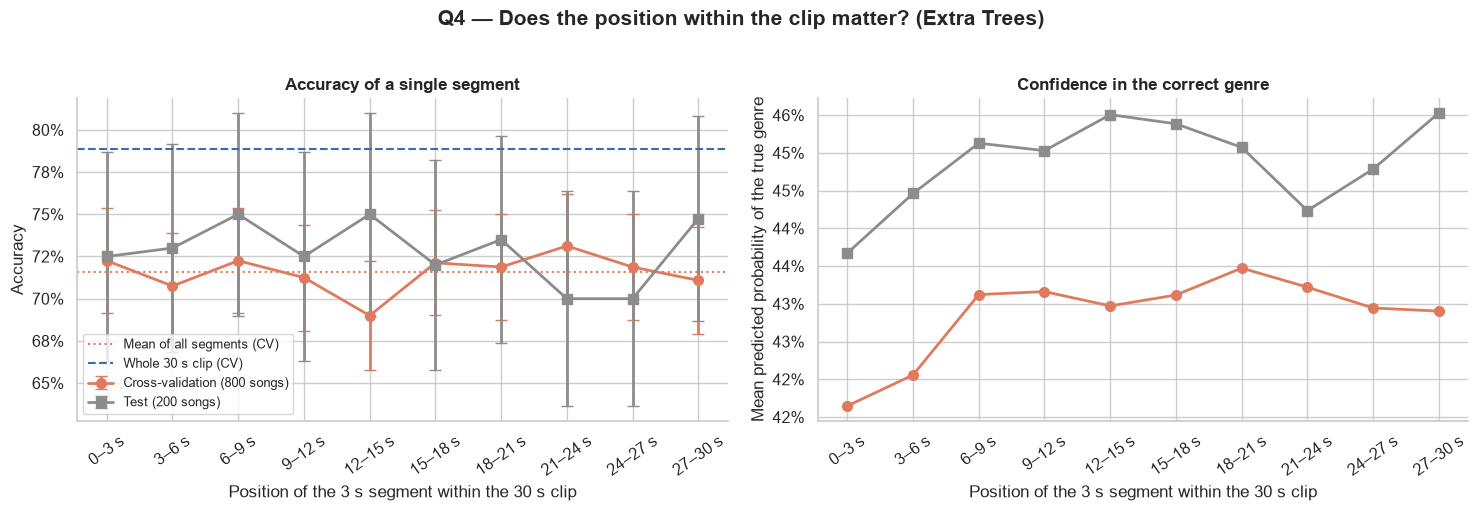

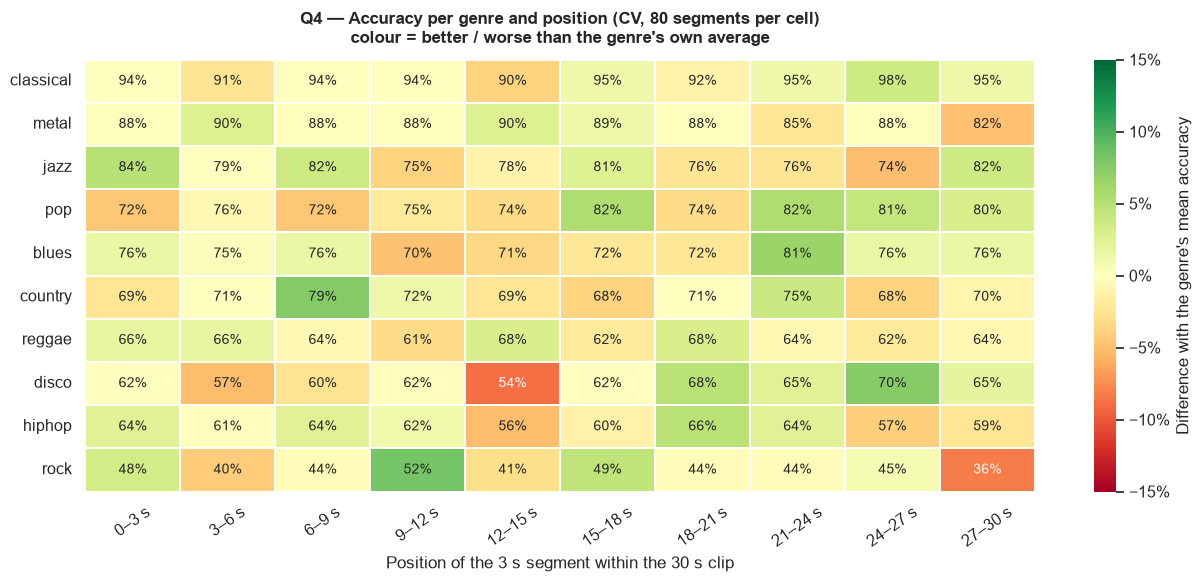

In [18]:
from scipy import stats
from matplotlib.ticker import PercentFormatter

seg_train = np.asarray(prep_3s.segments_train)      # position 0-9 of each segment
seg_test = np.asarray(prep_3s.segments_test)
y3_cv, y3_te = np.asarray(models_3.y), np.asarray(y_test_3s)
proba3_te = est3.predict_proba(X_test_3s)
POS_LABELS = [f"{3 * i}–{3 * i + 3} s" for i in range(10)]


# ============================================================
# 1. Accuracy and confidence per position
# ============================================================
def by_position(proba, y, seg):
    d = pd.DataFrame({
        "Segment": seg,
        "Correct": proba.argmax(1) == y,
        "P(true genre)": proba[np.arange(len(y)), y],   # confidence in the correct genre
    })
    t = d.groupby("Segment").agg(
        Accuracy=("Correct", "mean"),
        Segments=("Correct", "size"),
        **{"Mean P(true genre)": ("P(true genre)", "mean")},
    )
    t["95% CI"] = 1.96 * np.sqrt(t["Accuracy"] * (1 - t["Accuracy"]) / t["Segments"])
    return d, t


def cochran_q(d, songs):
    """Does accuracy depend on position? Paired test: the same song is compared across its 10 positions."""
    M = pd.crosstab(songs, d["Segment"], values=d["Correct"].astype(int), aggfunc="sum").dropna()
    X = M.values
    k, C, R, N = X.shape[1], X.sum(0), X.sum(1), X.sum()
    Q = (k - 1) * (k * (C ** 2).sum() - N ** 2) / (k * N - (R ** 2).sum())
    return Q, stats.chi2.sf(Q, k - 1), len(M)


d_cv, t_cv = by_position(proba3, y3_cv, seg_train)
d_te, t_te = by_position(proba3_te, y3_te, seg_test)

summary_q4 = pd.concat({"CV (800 songs)": t_cv, "Test (200 songs)": t_te}, axis=1)
summary_q4.index = POS_LABELS
display(summary_q4.round(3))

for name, d, songs in [("CV", d_cv, g_train_3s), ("Test", d_te, g_test_3s)]:
    Q, p, n = cochran_q(d, songs)
    acc = d.groupby("Segment")["Correct"].mean()
    print(f"{name}: accuracy from {acc.min():.3f} (segment {acc.idxmin()}) to {acc.max():.3f} "
          f"(segment {acc.idxmax()}) | Cochran's Q = {Q:.2f}, p = {p:.4f} ({n} songs)")

# ============================================================
# 2. Figure 1 — accuracy and confidence by position
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for t, label, color, marker in [(t_cv, "Cross-validation (800 songs)", C3, "o"),
                                (t_te, "Test (200 songs)", "#8C8C8C", "s")]:
    axes[0].errorbar(t.index, t["Accuracy"], yerr=t["95% CI"], fmt=f"{marker}-", color=color,
                     capsize=4, lw=2, ms=7, label=label)
    axes[1].plot(t.index, t["Mean P(true genre)"], f"{marker}-", color=color, lw=2, ms=7, label=label)

axes[0].axhline(d_cv["Correct"].mean(), ls=":", color=C3, lw=1.5, label="Mean of all segments (CV)")
axes[0].axhline(q2.loc["30 s clip", "CV acc"], ls="--", color=C30, lw=1.5, label="Whole 30 s clip (CV)")
axes[0].set_title("Accuracy of a single segment", weight="bold")
axes[0].set_ylabel("Accuracy")
axes[1].set_title("Confidence in the correct genre", weight="bold")
axes[1].set_ylabel("Mean predicted probability of the true genre")
for ax in axes:
    ax.set_xticks(range(10))
    ax.set_xticklabels(POS_LABELS, rotation=35)
    ax.set_xlabel("Position of the 3 s segment within the 30 s clip")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    sns.despine(ax=ax)
axes[0].legend(loc="lower left", fontsize=9, frameon=True)
fig.suptitle(f"Q4 — Does the position within the clip matter? ({best})",
             fontsize=15, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

# ============================================================
# 3. Figure 2 — position effect per genre (CV)
# ============================================================
acc_gp = (d_cv.assign(Genre=class_names[y3_cv])
          .pivot_table(index="Genre", columns="Segment", values="Correct", aggfunc="mean"))
acc_gp = acc_gp.loc[acc_gp.mean(axis=1).sort_values(ascending=False).index]
rel_gp = acc_gp.sub(acc_gp.mean(axis=1), axis=0)           # difference with the genre's own mean

plt.figure(figsize=(13, 6))
sns.heatmap(rel_gp, annot=acc_gp.map(lambda v: f"{v:.0%}"), fmt="", cmap="RdYlGn", center=0,
            vmin=-0.15, vmax=0.15, linewidths=1.2, linecolor="white", annot_kws={"size": 10},
            xticklabels=POS_LABELS,
            cbar_kws={"label": "Difference with the genre's mean accuracy",
                      "format": PercentFormatter(1.0, decimals=0)})
plt.title("Q4 — Accuracy per genre and position (CV, 80 segments per cell)\n"
          "colour = better / worse than the genre's own average", weight="bold", pad=12)
plt.xlabel("Position of the 3 s segment within the 30 s clip")
plt.ylabel("")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

From analysing the accuracy of the segments by position, we see that there is no significant difference between the performance of the different position. In cross-validation, single-segment accuracy only varies between 0.690 (12–15 s) and 0.731 (21–24 s), and on the test set between 0.700 and 0.750. All the 95% confidence intervals (±3 points in CV, ±6 on test) overlap with each other and with the overall mean of 0.716. The best and worst positions are also different in CV and test, which suggests the variation is noise rather than a real effect. 

Cochran’s Q test, which compares the 10 positions within the same songs, confirms this (CV: Q = 10.75, p = 0.29; test: Q = 5.57, p = 0.78). The only small pattern appears in the model’s confidence. The first two segments (0–6 s) receive a slightly lower probability for the true genre (0.42 vs about 0.43 in CV, with a similar trend on test), possibly because the excerpt starts at an arbitrary point in the song. The difference is only 1–2 points, however, and it does not change the accuracy. The per-genre heatmap shows larger fluctuations (for example, disco ranges from 54% to 70% and rock from 36% to 52%), but each cell contains only 80 segments, so its uncertainty is about ±11 points, and no genre is consistently easier at the beginning or the end of the clip. The order of genres is the same at every position: classical and metal are always the easiest and rock always the hardest, so the genre matters much more than the position. Finally, i believe that the 30-second excerpts are taken from arbitrary parts of each song, so “position 0” is not the song’s intro. Within these excerpts, every 3-second window is roughly equally informative, which also explains why combining them works well.

## Conclusions: 

The best model is Extra Trees with a correlation filter, both on the 30-second clips (0.789 CV, 0.800 test) and on the 3-second segments (0.716 CV, 0.728 test). Splitting the segments by song is essential: a random split inflates the 3-second accuracy by about 18 points, because the model recognises the song instead of the genre (Q5). A single 3-second window loses on average 5–8 points with respect to the whole clip. Timbre-defined genres (classical, jazz, metal) survive, while rhythm-defined genres (disco, rock, reggae, hip-hop) suffer most (Q1). Combining the ten windows of a song recovers about 70% of that loss and is not significantly worse than the 30-second clip, but it does not beat it (Q2). The position of the window within the clip does not matter (Q4). Overall, short windows contain most of the genre information, but the longer temporal patterns captured by the whole clip still give the best results.